In [28]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("Metro_Interstate_Traffic_Volume.csv")
print(df.head())
print("Dataset shape:", df.shape)
print(df.info())
print(df.isnull().sum())


   traffic_volume holiday    temp  rain_1h  snow_1h  clouds_all weather_main  \
0            5545     NaN  288.28      0.0      0.0          40       Clouds   
1            4516     NaN  289.36      0.0      0.0          75       Clouds   
2            4767     NaN  289.58      0.0      0.0          90       Clouds   
3            5026     NaN  290.13      0.0      0.0          90       Clouds   
4            4918     NaN  291.14      0.0      0.0          75       Clouds   

  weather_description         date_time  
0    scattered clouds  02-10-2012 09:00  
1       broken clouds  02-10-2012 10:00  
2     overcast clouds  02-10-2012 11:00  
3     overcast clouds  02-10-2012 12:00  
4       broken clouds  02-10-2012 13:00  
Dataset shape: (48204, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   traffic_volume       48204 n

In [29]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
traffic_volume             0
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
dtype: int64


In [30]:
print("Traffic Volume Statistics:")
print(df["traffic_volume"].describe())

Traffic Volume Statistics:
count    48204.000000
mean      3259.818355
std       1986.860670
min          0.000000
25%       1193.000000
50%       3380.000000
75%       4933.000000
max       7280.000000
Name: traffic_volume, dtype: float64


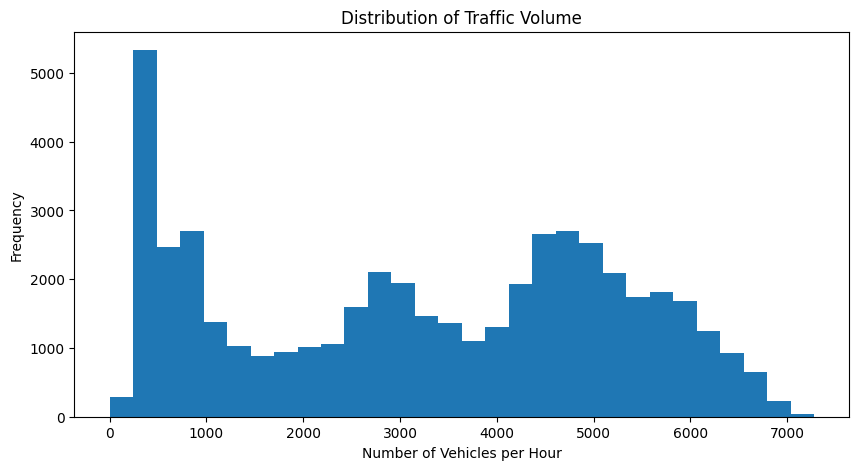

In [31]:
plt.figure(figsize=(10, 5))
plt.hist(df["traffic_volume"], bins=30)
plt.title("Distribution of Traffic Volume")
plt.xlabel("Number of Vehicles per Hour")
plt.ylabel("Frequency")
plt.show()

In [32]:
df_clean = df.copy()
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (48204, 9)
Working dataset shape: (48204, 9)


In [33]:
df_clean["holiday"] = df_clean["holiday"].fillna("None")
print("Missing holiday values:",
      df_clean["holiday"].isnull().sum())

Missing holiday values: 0


In [34]:
df_clean["date_time"] = pd.to_datetime(
    df_clean["date_time"],
    errors="coerce"
)
print("Data type:", df_clean["date_time"].dtype)
print(df_clean["date_time"].head())

Data type: datetime64[ns]
0   2012-02-10 09:00:00
1   2012-02-10 10:00:00
2   2012-02-10 11:00:00
3   2012-02-10 12:00:00
4   2012-02-10 13:00:00
Name: date_time, dtype: datetime64[ns]


In [35]:
print("Invalid timestamps:",
      df_clean["date_time"].isnull().sum())
df_clean = df_clean.dropna(subset=["date_time"]).copy()
print("Dataset shape:", df_clean.shape)

Invalid timestamps: 29270
Dataset shape: (18934, 9)


In [36]:
duplicates = df_clean.duplicated().sum()
print("Duplicate rows found:", duplicates)
df_clean = df_clean.drop_duplicates().copy()
print("Dataset shape after removing duplicates:", df_clean.shape)

Duplicate rows found: 6
Dataset shape after removing duplicates: (18928, 9)


In [37]:
# Final dataset verification
print("Final dataset shape:", df_clean.shape)
print("\nMissing values:")
print(df_clean.isnull().sum())
print("\nData types:")
print(df_clean.dtypes)
print("\nFirst 5 cleaned rows:")
display(df_clean.head())

Final dataset shape: (18928, 9)

Missing values:
traffic_volume         0
holiday                0
temp                   0
rain_1h                0
snow_1h                0
clouds_all             0
weather_main           0
weather_description    0
date_time              0
dtype: int64

Data types:
traffic_volume                  int64
holiday                        object
temp                          float64
rain_1h                       float64
snow_1h                       float64
clouds_all                      int64
weather_main                   object
weather_description            object
date_time              datetime64[ns]
dtype: object

First 5 cleaned rows:


,traffic_volume,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time
0,5545,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-02-10 09:00:00
1,4516,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-02-10 10:00:00
2,4767,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-02-10 11:00:00
3,5026,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-02-10 12:00:00
4,4918,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-02-10 13:00:00


In [38]:
# Save cleaned data as a CSV file
df_clean.to_csv("traffic_volume_cleaned.csv", index=False)
print("Day 2 data cleaning completed!")
print("File saved: traffic_volume_cleaned.csv")

Day 2 data cleaning completed!
File saved: traffic_volume_cleaned.csv


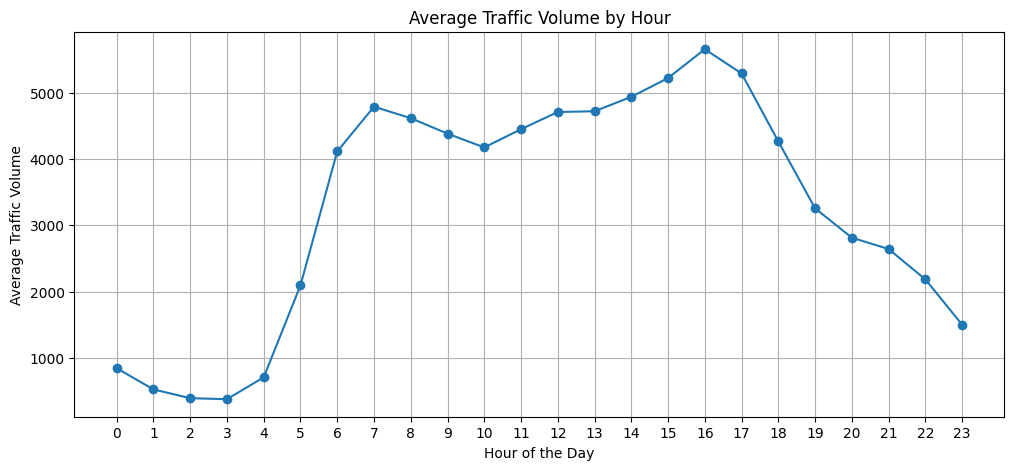

In [39]:
# Extract hour from date_time
df_clean["hour"] = df_clean["date_time"].dt.hour
hourly_traffic = df_clean.groupby("hour")["traffic_volume"].mean()
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))
plt.plot(hourly_traffic.index, hourly_traffic.values, marker="o")

plt.title("Average Traffic Volume by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Traffic Volume")
plt.xticks(range(24))
plt.grid(True)
plt.show()

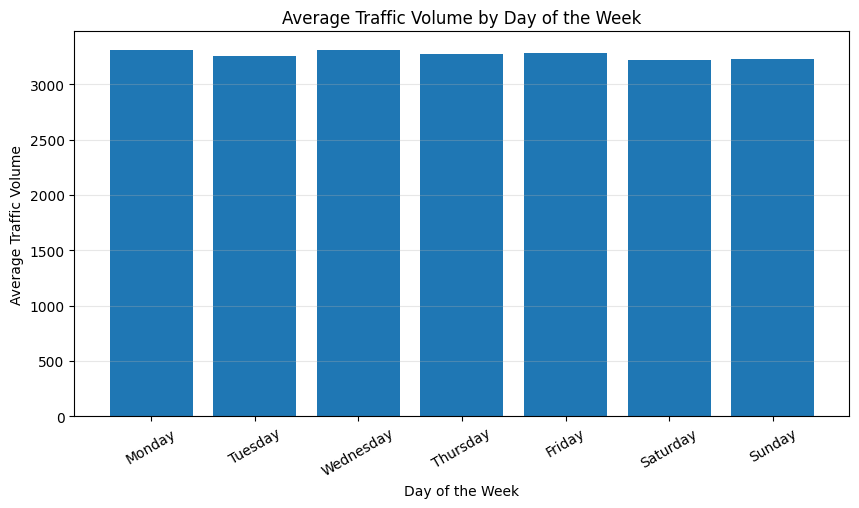

In [40]:
# Extract day of the week
df_clean["day_of_week"] = df_clean["date_time"].dt.day_name()
# Calculate average traffic for each day
daily_traffic = df_clean.groupby("day_of_week")["traffic_volume"].mean()
# Arrange days in the correct order
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]
daily_traffic = daily_traffic.reindex(day_order)
# Plotting the resut
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.bar(daily_traffic.index, daily_traffic.values)

plt.title("Average Traffic Volume by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Traffic Volume")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.show()

Average Traffic Volume by Weather:
weather_main
Clouds          3604.590281
Haze            3436.864043
Drizzle         3416.540931
Rain            3283.336984
Smoke           3103.722222
Clear           3080.431334
Snow            3073.292088
Mist            3002.089688
Fog             2940.592992
Thunderstorm    2837.905000
Squall          1818.000000
Name: traffic_volume, dtype: float64


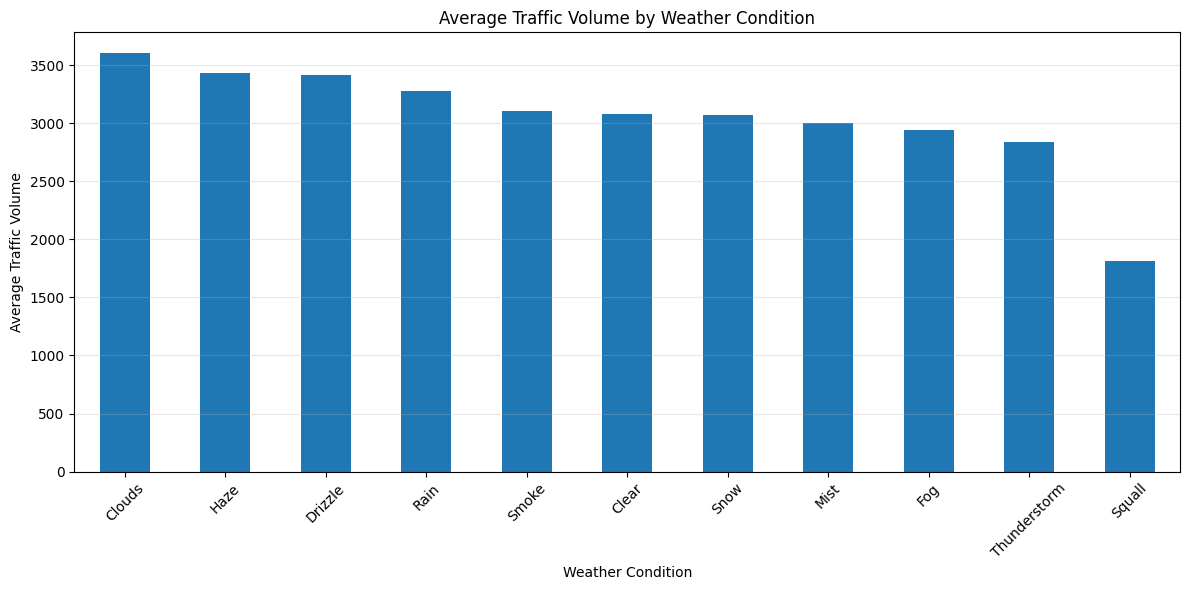

In [41]:
# Calculate average traffic volume by weather condition
weather_traffic = (
    df_clean.groupby("weather_main")["traffic_volume"]
    .mean()
    .sort_values(ascending=False)
)
# Display results
print("Average Traffic Volume by Weather:")
print(weather_traffic)
# Plot the results
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))
weather_traffic.plot(kind="bar")
plt.title("Average Traffic Volume by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Traffic Volume")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Average Traffic Volume by Month:
month
1     3228.472954
2     3242.425853
3     3319.200508
4     3192.080595
5     3195.951235
6     3323.642731
7     3340.882015
8     3347.191026
9     3341.943420
10    3285.964241
11    3125.118001
12    3273.352532
Name: traffic_volume, dtype: float64


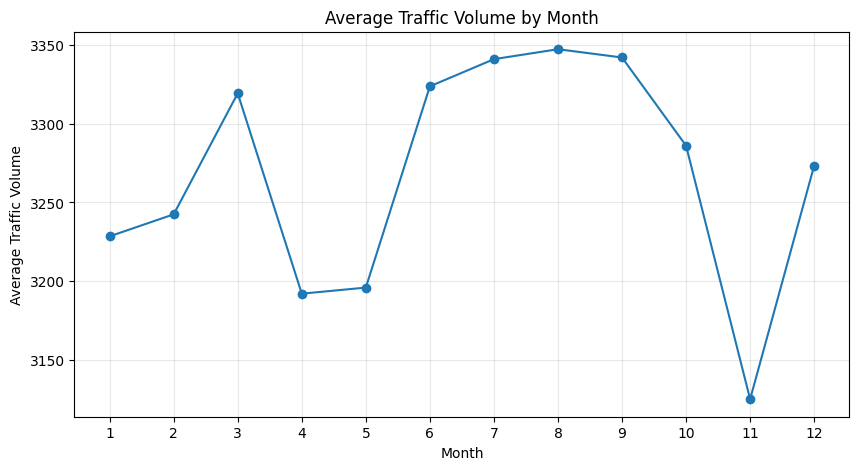

In [42]:
# Extract month from date_time
df_clean["month"] = df_clean["date_time"].dt.month

# Calculate average traffic volume by month
monthly_traffic = (
    df_clean.groupby("month")["traffic_volume"]
    .mean()
)
# Display results
print("Average Traffic Volume by Month:")
print(monthly_traffic)
# Plot monthly traffic
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_traffic.index,
    monthly_traffic.values,
    marker="o"
)
plt.title("Average Traffic Volume by Month")
plt.xlabel("Month")
plt.ylabel("Average Traffic Volume")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.show()

In [43]:
# Save dataset with EDA features
df_clean.to_csv("traffic_volume_eda.csv", index=False)
print("EDA dataset saved successfully!")
print("Rows and columns:", df_clean.shape)
print("New features: hour, day_of_week, month, day_type")

EDA dataset saved successfully!
Rows and columns: (18928, 12)
New features: hour, day_of_week, month, day_type


In [44]:
# Extract useful time features
df_clean["hour"] = df_clean["date_time"].dt.hour
df_clean["day_of_week"] = df_clean["date_time"].dt.dayofweek
df_clean["month"] = df_clean["date_time"].dt.month
df_clean["day"] = df_clean["date_time"].dt.day
df_clean["is_weekend"] = (
    df_clean["day_of_week"] >= 5
).astype(int)
print("Time features created successfully!")
display(df_clean[[
    "date_time",
    "hour",
    "day_of_week",
    "month",
    "day",
    "is_weekend",
    "traffic_volume"
]].head())

Time features created successfully!


,date_time,hour,day_of_week,month,day,is_weekend,traffic_volume
0,2012-02-10 09:00:00,9,4,2,10,0,5545
1,2012-02-10 10:00:00,10,4,2,10,0,4516
2,2012-02-10 11:00:00,11,4,2,10,0,4767
3,2012-02-10 12:00:00,12,4,2,10,0,5026
4,2012-02-10 13:00:00,13,4,2,10,0,4918


In [45]:
# Define target
target = "traffic_volume"
# Select features available in the dataset
feature_cols = [
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "hour",
    "day_of_week",
    "month",
    "day",
    "is_weekend",
    "holiday",
    "weather_main"
]
X = df_clean[feature_cols].copy()
y = df_clean[target].copy()
print("Input features shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())

Input features shape: (18928, 11)
Target shape: (18928,)


,temp,rain_1h,snow_1h,clouds_all,hour,day_of_week,month,day,is_weekend,holiday,weather_main
0,288.28,0.0,0.0,40,9,4,2,10,0,None,Clouds
1,289.36,0.0,0.0,75,10,4,2,10,0,None,Clouds
2,289.58,0.0,0.0,90,11,4,2,10,0,None,Clouds
3,290.13,0.0,0.0,90,12,4,2,10,0,None,Clouds
4,291.14,0.0,0.0,75,13,4,2,10,0,None,Clouds


In [46]:
# One-hot encode categorical features
X = pd.get_dummies(
    X,
    columns=["holiday", "weather_main"],
    dtype=int
)

print("Features after encoding:", X.shape[1])
display(X.head())

Features after encoding: 26


,temp,rain_1h,snow_1h,clouds_all,hour,day_of_week,month,day,is_weekend,holiday_Columbus Day,...,weather_main_Clouds,weather_main_Drizzle,weather_main_Fog,weather_main_Haze,weather_main_Mist,weather_main_Rain,weather_main_Smoke,weather_main_Snow,weather_main_Squall,weather_main_Thunderstorm
0,288.28,0.0,0.0,40,9,4,2,10,0,0,...,1,0,0,0,0,0,0,0,0,0
1,289.36,0.0,0.0,75,10,4,2,10,0,0,...,1,0,0,0,0,0,0,0,0,0
2,289.58,0.0,0.0,90,11,4,2,10,0,0,...,1,0,0,0,0,0,0,0,0,0
3,290.13,0.0,0.0,90,12,4,2,10,0,0,...,1,0,0,0,0,0,0,0,0,0
4,291.14,0.0,0.0,75,13,4,2,10,0,0,...,1,0,0,0,0,0,0,0,0,0


In [47]:
# Ensure observations are sorted by time
df_clean = df_clean.sort_values("date_time").reset_index(drop=True)

# Rebuild features and target in chronological order
X = df_clean[feature_cols].copy()
X = pd.get_dummies(
    X,
    columns=["holiday", "weather_main"],
    dtype=int
)
y = df_clean["traffic_volume"].copy()

# Use the first 80% for training and final 20% for testing
split_index = int(len(df_clean) * 0.8)
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:",
      df_clean["date_time"].iloc[0],
      "to",
      df_clean["date_time"].iloc[split_index - 1])
print("Testing period:",
      df_clean["date_time"].iloc[split_index],
      "to",
      df_clean["date_time"].iloc[-1])

Training rows: 15142
Testing rows: 3786
Training period: 2012-01-11 00:00:00 to 2017-10-12 00:00:00
Testing period: 2017-10-12 01:00:00 to 2018-12-09 23:00:00


In [48]:
print("Missing values in training features:", X_train.isnull().sum().sum())
print("Missing values in testing features:", X_test.isnull().sum().sum())
print("Missing training targets:", y_train.isnull().sum())
print("Missing testing targets:", y_test.isnull().sum())

print("\nFeature engineering completed!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Missing values in training features: 0
Missing values in testing features: 0
Missing training targets: 0
Missing testing targets: 0

Feature engineering completed!
Training data: (15142, 26)
Testing data: (3786, 26)


In [49]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [50]:
# Create the model
lr_model = LinearRegression()
# Train the model
lr_model.fit(X_train, y_train)
# Make predictions
lr_predictions = lr_model.predict(X_test)
print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [51]:
# Calculate evaluation metrics
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

print("Linear Regression Results")
print("--------------------------")
print(f"MAE:  {lr_mae:.2f}")
print(f"RMSE: {lr_rmse:.2f}")
print(f"R² Score: {lr_r2:.4f}")

Linear Regression Results
--------------------------
MAE:  1593.79
RMSE: 1809.77
R² Score: 0.1402


In [52]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


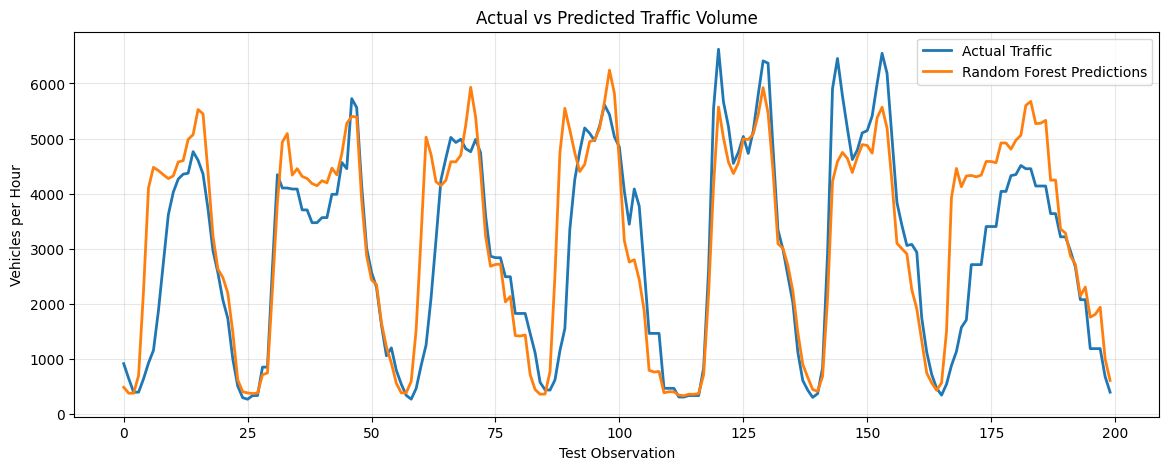

In [53]:
import matplotlib.pyplot as plt

# Display the first 200 test observations
n = min(200, len(y_test))
plt.figure(figsize=(14, 5))
plt.plot(
    np.arange(n),
    y_test.iloc[:n].values,
    label="Actual Traffic",
    linewidth=2
)
plt.plot(
    np.arange(n),
    rf_predictions[:n],
    label="Random Forest Predictions",
    linewidth=2
)
plt.title("Actual vs Predicted Traffic Volume")
plt.xlabel("Test Observation")
plt.ylabel("Vehicles per Hour")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [54]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [
        mean_absolute_error(y_test, lr_predictions),
        mean_absolute_error(y_test, rf_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, lr_predictions)),
        np.sqrt(mean_squared_error(y_test, rf_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, lr_predictions),
        r2_score(y_test, rf_predictions)
    ]
})
display(results.round(3))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1593.788,1809.775,0.14
1,Random Forest,626.890,936.307,0.77


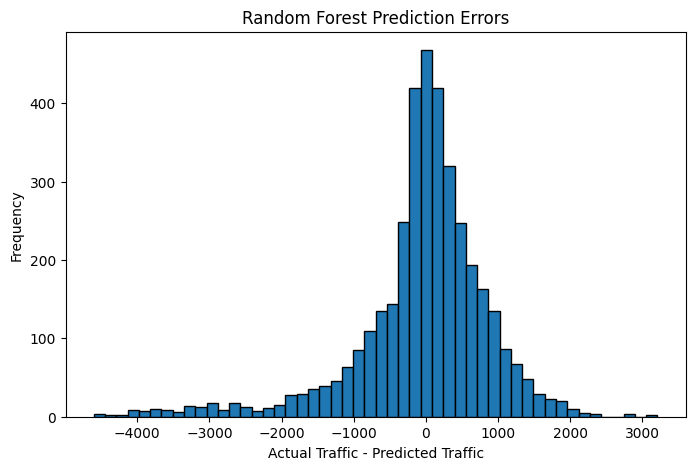

In [55]:
import matplotlib.pyplot as plt
rf_errors = np.array(y_test) - rf_predictions
plt.figure(figsize=(8, 5))
plt.hist(rf_errors, bins=50, edgecolor="black")
plt.title("Random Forest Prediction Errors")
plt.xlabel("Actual Traffic - Predicted Traffic")
plt.ylabel("Frequency")
plt.show()

,0
hour,0.863619
temp,0.047066
month,0.026507
day,0.018074
day_of_week,0.015038
clouds_all,0.012360
rain_1h,0.005631
weather_main_Clouds,0.003308
is_weekend,0.001841
weather_main_Clear,0.001803


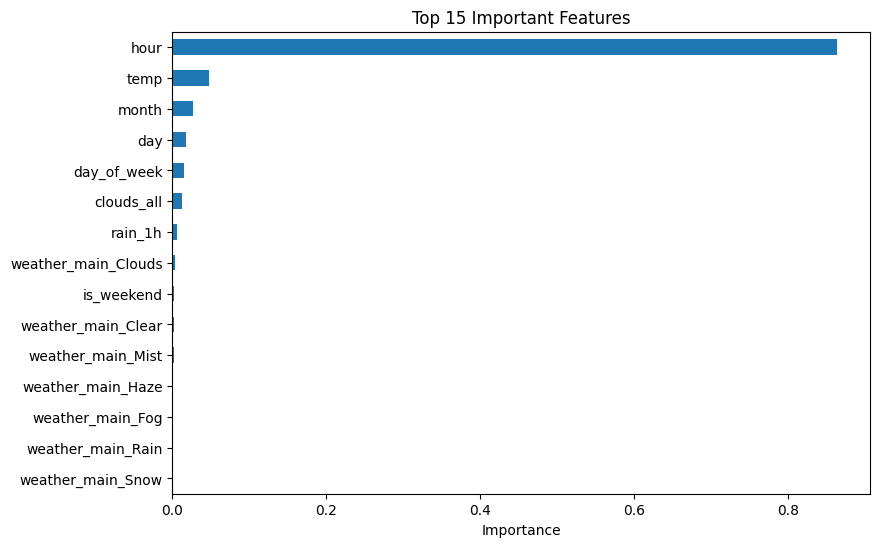

In [56]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)
display(feature_importance.head(15))
feature_importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title="Top 15 Important Features"
)
plt.xlabel("Importance")
plt.show()

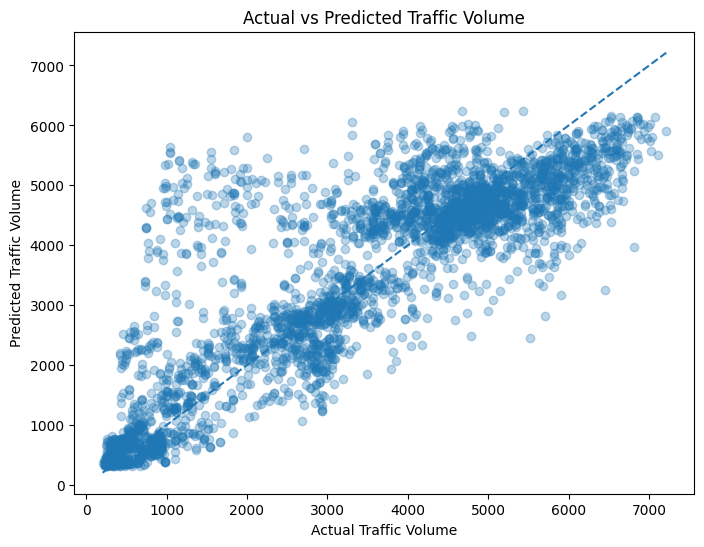

In [57]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.3
)
plt.title("Actual vs Predicted Traffic Volume")
plt.xlabel("Actual Traffic Volume")
plt.ylabel("Predicted Traffic Volume")
min_value = min(np.min(y_test), np.min(rf_predictions))
max_value = max(np.max(y_test), np.max(rf_predictions))
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)
plt.show()

In [58]:
import joblib
lr_mae = mean_absolute_error(y_test, lr_predictions)
rf_mae = mean_absolute_error(y_test, rf_predictions)
if rf_mae < lr_mae:
    best_model = rf_model
    best_model_name = "Random Forest"
else:
    best_model = lr_model
    best_model_name = "Linear Regression"
joblib.dump(best_model, "best_traffic_model.pkl")
print("Selected model:", best_model_name)
print("Model saved successfully!")

Selected model: Random Forest
Model saved successfully!


In [59]:
results.to_csv("model_evaluation_results.csv", index=False)
print("Evaluation results saved!")

Evaluation results saved!


In [60]:
print(results)

               Model          MAE         RMSE  R2 Score
0  Linear Regression  1593.788277  1809.774519  0.140158
1      Random Forest   626.890298   936.307278  0.769852


In [61]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
print("Linear Regression:")
print("MAE:", mean_absolute_error(y_test, lr_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_predictions)))
print("R²:", r2_score(y_test, lr_predictions))
print("\nRandom Forest:")
print("MAE:", mean_absolute_error(y_test, rf_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_predictions)))
print("R²:", r2_score(y_test, rf_predictions))

Linear Regression:
MAE: 1593.7882766479513
RMSE: 1809.7745185489832
R²: 0.14015842714239857

Random Forest:
MAE: 626.8902978037246
RMSE: 936.3072777667649
R²: 0.7698524801262546
